Step 1: Download CIFAR-10 in Google Colab

In [6]:
#importing all the needed libraries
import torch
import torchvision
import matplotlib.pyplot as plt
from torchvision import datasets, transforms


# Check installed PyTorch version
print(f"PyTorch version: {torch.__version__}")

# Check if GPU acceleration is available
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Convert images into PyTorch tensors
data_transform = transforms.Compose([
    transforms.ToTensor()
])

# Download the CIFAR-10 training dataset
train_data = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=data_transform
)

# Download the CIFAR-10 testing dataset
test_data = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=data_transform
)

# Verify the downloaded datasets
print(f"Training images: {len(train_data)}")
print(f"Testing images: {len(test_data)}")
print(f"Class names: {train_data.classes}")


PyTorch version: 2.11.0+cu130
Using device: cuda
Training images: 50000
Testing images: 10000
Class names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


2. Step 2: Explore and visualize our dataset

Image shape: torch.Size([3, 32, 32])
Image label: 6
Class name: frog


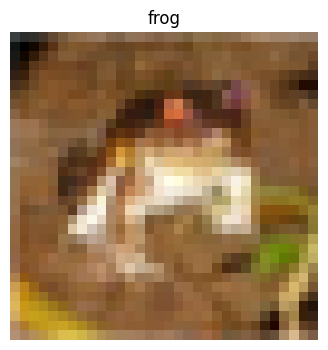

In [5]:

# Get the class names from the CIFAR-10 dataset
class_names = train_data.classes

# Select the first image and its corresponding label
image, label = train_data[0]

# Display information about the image
print(f"Image shape: {image.shape}")
print(f"Image label: {label}")
print(f"Class name: {class_names[label]}")

# Display the first image
plt.figure(figsize=(4, 4))

# Convert tensor from [C, H, W] to [H, W, C]
plt.imshow(image.permute(1, 2, 0))

# Display the correct class name
plt.title(class_names[label])

# Remove axis markings
plt.axis("off")

# Show the image
plt.show()


2. Step 3: Visualize multiple images from CIFAR-10

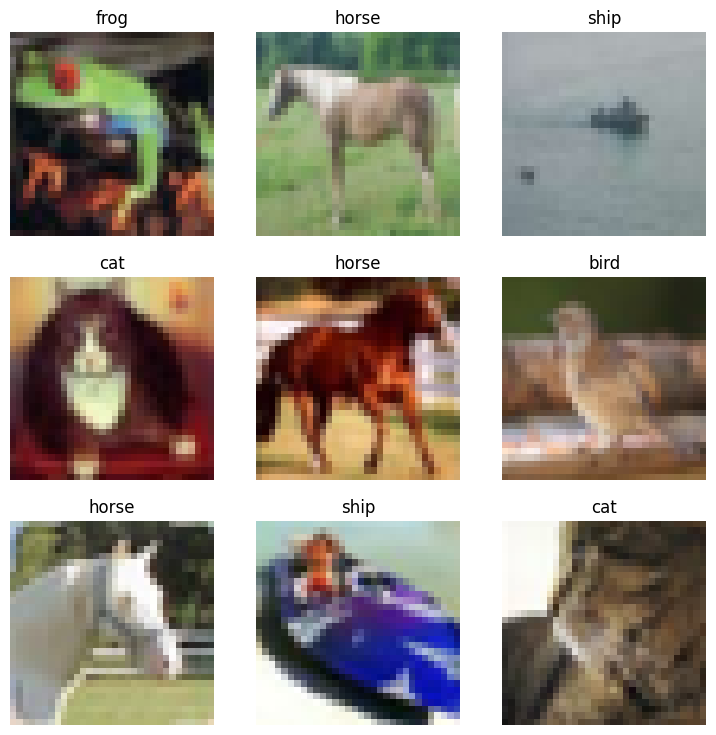

In [7]:
# Set the random seed for reproducible results
torch.manual_seed(42)

# Create a figure to display 9 images
fig = plt.figure(figsize=(9, 9))

# Select 9 random images from the training dataset
for i in range(1, 10):

    # Generate a random image index
    random_idx = torch.randint(
        0, len(train_data), size=[1]
    ).item()

    # Get the image and its label
    image, label = train_data[random_idx]

    # Create a subplot for each image
    fig.add_subplot(3, 3, i)

    # Convert image from [C, H, W] to [H, W, C]
    plt.imshow(image.permute(1, 2, 0))

    # Display the class name above the image
    plt.title(class_names[label])

    # Hide the axes
    plt.axis("off")

# Display all 9 images
plt.show()


Step 4: Split our CIFAR-10 dataset

Step 4A: Create training and validation datasets

In [8]:
from torch.utils.data import random_split

# Set the random seed for reproducible results
torch.manual_seed(42)

# Define the number of images for each dataset
train_size = 45000
val_size = 5000

# Split the original CIFAR-10 training dataset
# into training and validation subsets
train_dataset, val_dataset = random_split(
    train_data,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# Keep the official CIFAR-10 test dataset separate
test_dataset = test_data

# Verify the number of images in each dataset
print(f"Training dataset: {len(train_dataset)} images")
print(f"Validation dataset: {len(val_dataset)} images")
print(f"Testing dataset: {len(test_dataset)} images")

# Verify that all images are accounted for
total_images = (
    len(train_dataset)
    + len(val_dataset)
    + len(test_dataset)
)

print(f"Total images: {total_images}")


Training dataset: 45000 images
Validation dataset: 5000 images
Testing dataset: 10000 images
Total images: 60000


Step 4B: Verify that the subsets do not overlap

In [9]:

# Convert training and validation indices into sets
train_indices = set(train_dataset.indices)
val_indices = set(val_dataset.indices)

# Check for overlapping image indices
overlap = train_indices.intersection(val_indices)

# Display the number of overlapping images
print(f"Overlapping images: {len(overlap)}")

# Verify the split covers the original training set
print(
    f"Combined training and validation images: "
    f"{len(train_indices.union(val_indices))}"
)


Overlapping images: 0
Combined training and validation images: 50000


Step 5A: Create the DataLoaders

In [10]:

from torch.utils.data import DataLoader

# Set the batch size for model training
BATCH_SIZE = 32

# Create the training DataLoader
# Shuffle the training images to improve learning
train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# Create the validation DataLoader
# Shuffling is unnecessary during validation
val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Create the testing DataLoader
# Keep the testing order consistent for evaluation
test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Display the number of batches in each DataLoader
print(f"Training batches: {len(train_dataloader)}")
print(f"Validation batches: {len(val_dataloader)}")
print(f"Testing batches: {len(test_dataloader)}")


Training batches: 1407
Validation batches: 157
Testing batches: 313


Step 5B: Inspect one batch

In [11]:

# Retrieve one batch from the training DataLoader
train_features_batch, train_labels_batch = next(
    iter(train_dataloader)
)

# Display the shape of the image batch
print(
    f"Feature batch shape: "
    f"{train_features_batch.shape}"
)

# Display the shape of the label batch
print(
    f"Label batch shape: "
    f"{train_labels_batch.shape}"
)

# Display the first image's class label
print(
    f"First image class: "
    f"{class_names[train_labels_batch[0].item()]}"
)


Feature batch shape: torch.Size([32, 3, 32, 32])
Label batch shape: torch.Size([32])
First image class: cat


Step 6: Build our TinyVGG CNN model

In [12]:

from torch import nn

# Create a TinyVGG convolutional neural network
# Adapted from the instructor's model_builder.py
class TinyVGG(nn.Module):

    def __init__(
        self,
        input_shape: int,
        hidden_units: int,
        output_shape: int
    ):
        super().__init__()

        # First convolutional block
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(
                in_channels=input_shape,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=0
            ),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=0
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Second convolutional block
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=0
            ),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=0
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Classifier adapted for 32x32 CIFAR-10 images
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                in_features=hidden_units * 5 * 5,
                out_features=output_shape
            )
        )

    # Define how images move through the network
    def forward(self, x: torch.Tensor):

        # Pass images through the first block
        x = self.conv_block_1(x)

        # Pass features through the second block
        x = self.conv_block_2(x)

        # Generate the final class scores
        x = self.classifier(x)

        return x


Step 6B: Create the model

In [13]:

# Set the random seed for reproducibility
torch.manual_seed(42)

# Select GPU if available, otherwise use CPU
device = "cuda" if torch.cuda.is_available() else "cpu"

# Create the TinyVGG model for CIFAR-10
model = TinyVGG(
    input_shape=3,
    hidden_units=10,
    output_shape=len(class_names)
).to(device)

# Display the model architecture
print(model)

# Display the device being used
print(f"\nModel device: {next(model.parameters()).device}")


TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=250, out_features=10, bias=True)
  )
)

Model device: cuda:0


Step 6C: Test the model with one batch

In [14]:

# Put the model into evaluation mode
model.eval()

# Disable gradient calculations for this test
with torch.inference_mode():

    # Move one image batch to the same device as the model
    sample_images = train_features_batch.to(device)

    # Pass the images through TinyVGG
    sample_outputs = model(sample_images)

# Display input and output shapes
print(f"Input shape: {sample_images.shape}")
print(f"Output shape: {sample_outputs.shape}")


Input shape: torch.Size([32, 3, 32, 32])
Output shape: torch.Size([32, 10])


Step 7: Define the loss function and optimizer

7A: Configure the loss function and optimizer

In [15]:
from torch import nn

# Define the loss function for multiclass classification
loss_fn = nn.CrossEntropyLoss()

# Define the Adam optimizer to update model parameters
optimizer = torch.optim.Adam(
    params=model.parameters(),
    lr=0.001
)

# Set the initial maximum number of training epochs
NUM_EPOCHS = 10

# Display the training configuration
print(f"Loss function: {loss_fn}")
print(f"Optimizer: {optimizer.__class__.__name__}")
print(f"Learning rate: {optimizer.param_groups[0]['lr']}")
print(f"Maximum epochs: {NUM_EPOCHS}")
print(f"Training device: {device}")


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Maximum epochs: 10
Training device: cuda


Step 7B: Configure early stopping

In [16]:

# Number of consecutive epochs allowed without improvement
PATIENCE = 3

# Minimum improvement required in validation loss
MIN_DELTA = 0.001

# Track the best validation loss
best_val_loss = float("inf")

# Count epochs without sufficient improvement
epochs_without_improvement = 0

# Display early stopping configuration
print(f"Early stopping patience: {PATIENCE}")
print(f"Minimum improvement: {MIN_DELTA}")


Early stopping patience: 3
Minimum improvement: 0.001


Step 8A: Create the training function

In [17]:

# Train the model for one complete epoch
def train_step(
    model,
    dataloader,
    loss_fn,
    optimizer,
    device
):
    # Put the model into training mode
    model.train()

    # Initialize loss and accuracy
    train_loss = 0
    train_acc = 0

    # Loop through batches of training data
    for batch, (X, y) in enumerate(dataloader):

        # Move images and labels to the GPU
        X, y = X.to(device), y.to(device)

        # Perform the forward pass
        y_pred = model(X)

        # Calculate the training loss
        loss = loss_fn(y_pred, y)

        # Reset gradients from the previous batch
        optimizer.zero_grad()

        # Calculate gradients using backpropagation
        loss.backward()

        # Update the model parameters
        optimizer.step()

        # Accumulate the batch loss
        train_loss += loss.item()

        # Convert class scores into predicted labels
        y_pred_class = torch.argmax(
            torch.softmax(y_pred, dim=1),
            dim=1
        )

        # Calculate batch accuracy
        train_acc += (
            y_pred_class == y
        ).sum().item() / len(y_pred)

    # Calculate average loss and accuracy
    train_loss /= len(dataloader)
    train_acc /= len(dataloader)

    return train_loss, train_acc


Step 8B: Create the validation function

In [18]:

# Evaluate the model on validation images
def validation_step(
    model,
    dataloader,
    loss_fn,
    device
):
    # Put the model into evaluation mode
    model.eval()

    # Initialize validation loss and accuracy
    val_loss = 0
    val_acc = 0

    # Disable gradient calculations
    with torch.inference_mode():

        # Loop through validation batches
        for batch, (X, y) in enumerate(dataloader):

            # Move images and labels to the GPU
            X, y = X.to(device), y.to(device)

            # Perform the forward pass
            val_pred_logits = model(X)

            # Calculate validation loss
            loss = loss_fn(val_pred_logits, y)

            # Accumulate validation loss
            val_loss += loss.item()

            # Convert logits into predicted labels
            val_pred_labels = val_pred_logits.argmax(dim=1)

            # Calculate validation accuracy
            val_acc += (
                val_pred_labels == y
            ).sum().item() / len(val_pred_labels)

    # Calculate average validation loss and accuracy
    val_loss /= len(dataloader)
    val_acc /= len(dataloader)

    return val_loss, val_acc


Step 8C: Verify the functions

In [19]:

# Confirm the training function was created
print("Training function:", train_step.__name__)

# Confirm the validation function was created
print("Validation function:", validation_step.__name__)

# Verify that our DataLoaders are available
print("Training batches:", len(train_dataloader))
print("Validation batches:", len(val_dataloader))

# Verify the model device
print("Model device:", next(model.parameters()).device)


Training function: train_step
Validation function: validation_step
Training batches: 1407
Validation batches: 157
Model device: cuda:0


Step 9A: Connect Google Drive

In [20]:

from google.colab import drive
from pathlib import Path

# Connect Google Drive to Google Colab
drive.mount("/content/drive")

# Create a permanent project directory
project_path = Path("/content/drive/MyDrive/SmartVision")

# Create a folder for model checkpoints
model_path = project_path / "models"

# Create the directories if they do not exist
model_path.mkdir(parents=True, exist_ok=True)

# Display the checkpoint directory
print(f"Model directory: {model_path}")


Mounted at /content/drive
Model directory: /content/drive/MyDrive/SmartVision/models


Step 9B: Create the full training loop

In [21]:

import time
import torch

# Store training results for later visualization
results = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

# Reset early stopping variables
best_val_loss = float("inf")
epochs_without_improvement = 0

# Define the location for saving the best model
checkpoint_path = model_path / "smartvision_best_model.pth"

# Record the starting time
start_time = time.perf_counter()

# Train for a maximum of 10 epochs
for epoch in range(NUM_EPOCHS):

    # Train the model for one epoch
    train_loss, train_acc = train_step(
        model=model,
        dataloader=train_dataloader,
        loss_fn=loss_fn,
        optimizer=optimizer,
        device=device
    )

    # Evaluate the model on validation data
    val_loss, val_acc = validation_step(
        model=model,
        dataloader=val_dataloader,
        loss_fn=loss_fn,
        device=device
    )

    # Save metrics for plotting
    results["train_loss"].append(train_loss)
    results["train_acc"].append(train_acc)
    results["val_loss"].append(val_loss)
    results["val_acc"].append(val_acc)

    # Display training progress
    print(
        f"Epoch: {epoch + 1}/{NUM_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.4f}",
        flush=True
    )

    # Check whether validation loss improved
    if val_loss < best_val_loss - MIN_DELTA:

        # Update the best validation loss
        best_val_loss = val_loss

        # Reset early stopping counter
        epochs_without_improvement = 0

        # Save the best model weights to Google Drive
        torch.save(
            model.state_dict(),
            checkpoint_path
        )

        print("Best model saved.", flush=True)

    else:

        # Count epochs without improvement
        epochs_without_improvement += 1

        print(
            f"No improvement: "
            f"{epochs_without_improvement}/{PATIENCE}",
            flush=True
        )

        # Stop if validation loss has not improved
        if epochs_without_improvement >= PATIENCE:
            print("Early stopping triggered.")
            break

# Calculate total training time
total_training_time = time.perf_counter() - start_time

print(f"\nTraining completed in {total_training_time:.2f} seconds")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best model saved to: {checkpoint_path}")


Epoch: 1/10 | Train loss: 1.9590 | Train acc: 0.2701 | Val loss: 1.6678 | Val acc: 0.3873
Best model saved.
Epoch: 2/10 | Train loss: 1.5553 | Train acc: 0.4362 | Val loss: 1.5314 | Val acc: 0.4471
Best model saved.
Epoch: 3/10 | Train loss: 1.4503 | Train acc: 0.4779 | Val loss: 1.4231 | Val acc: 0.4869
Best model saved.
Epoch: 4/10 | Train loss: 1.3964 | Train acc: 0.4988 | Val loss: 1.3910 | Val acc: 0.5008
Best model saved.
Epoch: 5/10 | Train loss: 1.3528 | Train acc: 0.5197 | Val loss: 1.3892 | Val acc: 0.5012
Best model saved.
Epoch: 6/10 | Train loss: 1.3181 | Train acc: 0.5296 | Val loss: 1.3169 | Val acc: 0.5291
Best model saved.
Epoch: 7/10 | Train loss: 1.2879 | Train acc: 0.5411 | Val loss: 1.3132 | Val acc: 0.5283
Best model saved.
Epoch: 8/10 | Train loss: 1.2601 | Train acc: 0.5527 | Val loss: 1.2735 | Val acc: 0.5434
Best model saved.
Epoch: 9/10 | Train loss: 1.2351 | Train acc: 0.5651 | Val loss: 1.2670 | Val acc: 0.5402
Best model saved.
Epoch: 10/10 | Train loss: 1

Step 10: Plot training and validation loss

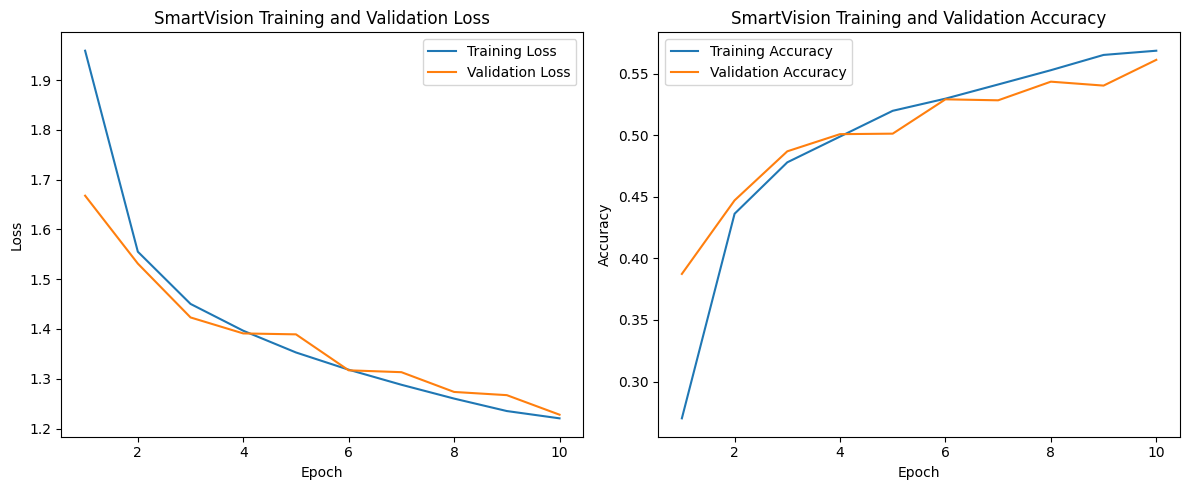

In [22]:

# Create epoch numbers from the training history
epochs = range(1, len(results["train_loss"]) + 1)

# Create two plots side by side
plt.figure(figsize=(12, 5))

# Plot training and validation loss
plt.subplot(1, 2, 1)

plt.plot(
    epochs,
    results["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs,
    results["val_loss"],
    label="Validation Loss"
)

plt.title("SmartVision Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# Plot training and validation accuracy
plt.subplot(1, 2, 2)

plt.plot(
    epochs,
    results["train_acc"],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    results["val_acc"],
    label="Validation Accuracy"
)

plt.title("SmartVision Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Adjust spacing and display both plots
plt.tight_layout()
plt.show()


Step 11: Load the best saved model

In [23]:

# Locate the best model checkpoint
checkpoint_path = (
    model_path / "smartvision_best_model.pth"
)

# Load the best model weights
model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

# Move the model to the selected device
model = model.to(device)

# Put the model into evaluation mode
model.eval()

# Confirm the checkpoint was loaded
print("Best SmartVision model loaded successfully.")
print(f"Checkpoint: {checkpoint_path}")
print(f"Model device: {next(model.parameters()).device}")


Best SmartVision model loaded successfully.
Checkpoint: /content/drive/MyDrive/SmartVision/models/smartvision_best_model.pth
Model device: cuda:0


Step 12: Evaluate SmartVision on the official CIFAR-10 test dataset.

Step 12A: Calculate test accuracy, precision, recall, and F1-score

In [24]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Put the trained model into evaluation mode
model.eval()

# Store actual and predicted class labels
y_true = []
y_pred = []

# Disable gradient calculations during testing
with torch.inference_mode():

    # Loop through all batches in the test dataset
    for X, y in test_dataloader:

        # Move test images to the GPU
        X = X.to(device)

        # Generate predictions using the trained model
        test_logits = model(X)

        # Select the class with the highest score
        test_predictions = test_logits.argmax(dim=1)

        # Store actual labels
        y_true.extend(y.cpu().tolist())

        # Store predicted labels
        y_pred.extend(test_predictions.cpu().tolist())

# Calculate overall test accuracy
test_accuracy = accuracy_score(y_true, y_pred)

# Calculate weighted precision
test_precision = precision_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

# Calculate weighted recall
test_recall = recall_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

# Calculate weighted F1-score
test_f1 = f1_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

# Display evaluation results
print("SmartVision Final Test Results")
print("------------------------------")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test precision: {test_precision:.4f}")
print(f"Test recall: {test_recall:.4f}")
print(f"Test F1-score: {test_f1:.4f}")

# Display detailed performance for each class
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)


SmartVision Final Test Results
------------------------------
Test accuracy: 0.5744
Test precision: 0.5740
Test recall: 0.5744
Test F1-score: 0.5705

Classification Report:
              precision    recall  f1-score   support

    airplane       0.62      0.58      0.60      1000
  automobile       0.67      0.74      0.70      1000
        bird       0.52      0.35      0.42      1000
         cat       0.41      0.41      0.41      1000
        deer       0.51      0.44      0.48      1000
         dog       0.45      0.55      0.50      1000
        frog       0.60      0.75      0.67      1000
       horse       0.61      0.62      0.62      1000
        ship       0.70      0.64      0.67      1000
       truck       0.65      0.66      0.65      1000

    accuracy                           0.57     10000
   macro avg       0.57      0.57      0.57     10000
weighted avg       0.57      0.57      0.57     10000



Step 12B: Create a confusion matrix

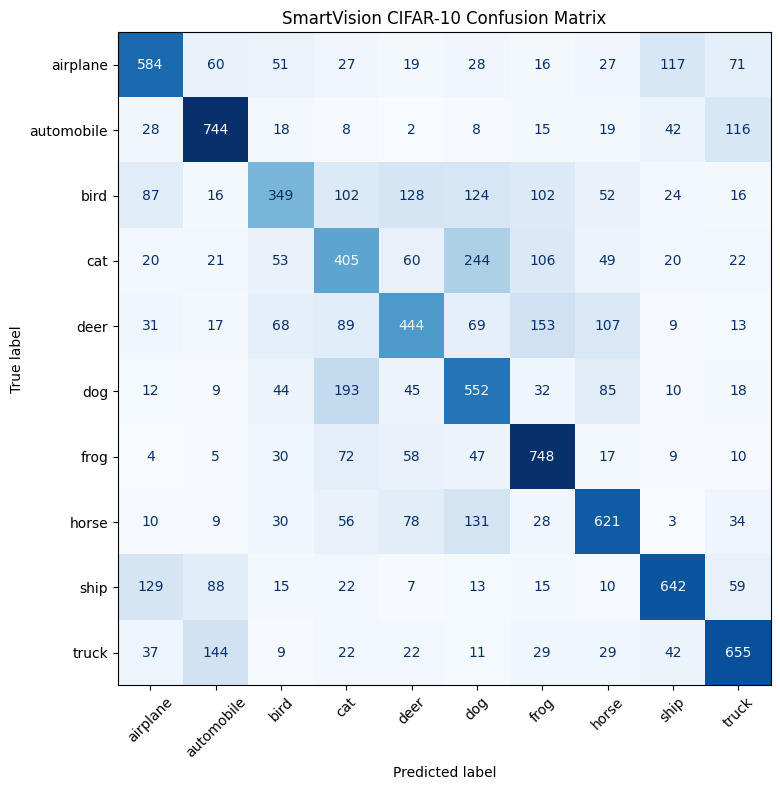

In [25]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calculate the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Create the confusion matrix visualization
fig, ax = plt.subplots(figsize=(10, 8))

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    ax=ax,
    xticks_rotation=45,
    colorbar=False
)

# Add a descriptive title
plt.title("SmartVision CIFAR-10 Confusion Matrix")

# Adjust spacing
plt.tight_layout()

# Display the visualization
plt.show()


13A: Predict one image and measure its inference time

Actual class: cat
Predicted class: cat
Confidence: 73.28%
Inference time: 0.000717 seconds


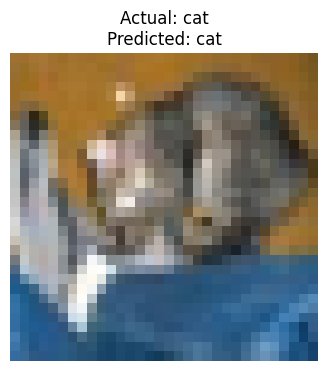

In [26]:

import torch
import time
import matplotlib.pyplot as plt

# Select the first image from the official test dataset
image, label = test_dataset[0]

# Add a batch dimension:
# [3, 32, 32] becomes [1, 3, 32, 32]
image_batch = image.unsqueeze(dim=0).to(device)

# Put the trained model into evaluation mode
model.eval()

# Warm up the GPU before measuring inference
with torch.inference_mode():
    for _ in range(5):
        _ = model(image_batch)

# Wait for GPU operations to finish
if device == "cuda":
    torch.cuda.synchronize()

# Start the inference timer
start_time = time.perf_counter()

# Generate the prediction without calculating gradients
with torch.inference_mode():
    prediction_logits = model(image_batch)

# Wait for GPU operations to finish before stopping timer
if device == "cuda":
    torch.cuda.synchronize()

# Stop the timer
inference_time = time.perf_counter() - start_time

# Convert logits into class probabilities
prediction_probs = torch.softmax(
    prediction_logits,
    dim=1
)

# Select the class with the highest probability
predicted_label = prediction_probs.argmax(dim=1).item()

# Get the prediction confidence
confidence = prediction_probs.max().item()

# Display prediction results
print(f"Actual class: {class_names[label]}")
print(f"Predicted class: {class_names[predicted_label]}")
print(f"Confidence: {confidence:.2%}")
print(f"Inference time: {inference_time:.6f} seconds")

# Display the test image
plt.figure(figsize=(4, 4))
plt.imshow(image.permute(1, 2, 0))
plt.title(
    f"Actual: {class_names[label]}\n"
    f"Predicted: {class_names[predicted_label]}"
)
plt.axis("off")
plt.show()


Step 14A: Create the Gradio prediction function

In [27]:

import time
import torch
from torchvision import transforms

# Define preprocessing for uploaded images
# Match the preprocessing used during model training
predict_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

# Create a function for classifying uploaded images
def predict_image(image):

    # Start timing the complete prediction process
    start_time = time.perf_counter()

    # Convert the uploaded PIL image into a tensor
    image_tensor = predict_transform(image)

    # Add a batch dimension and move to the model device
    image_tensor = image_tensor.unsqueeze(0).to(device)

    # Put the model into evaluation mode
    model.eval()

    # Make a prediction without calculating gradients
    with torch.inference_mode():
        prediction_logits = model(image_tensor)

    # Convert class scores into probabilities
    prediction_probs = torch.softmax(
        prediction_logits,
        dim=1
    )

    # Convert probabilities into a class dictionary
    prediction_dict = {
        class_names[i]: float(prediction_probs[0][i])
        for i in range(len(class_names))
    }

    # Synchronize GPU operations before stopping timer
    if device == "cuda":
        torch.cuda.synchronize()

    # Calculate total inference time in seconds
    prediction_time = time.perf_counter() - start_time

    # Return probabilities and prediction time
    return prediction_dict, prediction_time


Step 14B: Test the prediction function

In [28]:

from PIL import Image

# Retrieve an image from the CIFAR-10 test dataset
test_image, test_label = test_dataset[0]

# Convert the image tensor into a PIL image
pil_image = transforms.ToPILImage()(test_image)

# Run the prediction function
prediction_dict, prediction_time = predict_image(pil_image)

# Find the class with the highest probability
predicted_class = max(
    prediction_dict,
    key=prediction_dict.get
)

# Display the prediction results
print(f"Actual class: {class_names[test_label]}")
print(f"Predicted class: {predicted_class}")
print(
    f"Confidence: "
    f"{prediction_dict[predicted_class]:.2%}"
)
print(f"Prediction time: {prediction_time:.6f} seconds")


Actual class: cat
Predicted class: cat
Confidence: 73.28%
Prediction time: 0.003507 seconds


Step 15: Build the Gradio web interface

In [29]:
# Install Gradio for building the web application
!pip install -q gradio


Step 15B: Create the Gradio interface

In [30]:

import gradio as gr

# Create the SmartVision web application
demo = gr.Interface(
    fn=predict_image,

    # Allow users to upload an image
    inputs=gr.Image(
        type="pil",
        label="Upload an Image"
    ),

    # Display classification probabilities and time
    outputs=[
        gr.Label(
            num_top_classes=3,
            label="Predicted Object Classes"
        ),
        gr.Number(
            label="Prediction Time (seconds)"
        )
    ],

    # Add a descriptive application title
    title="SmartVision — CIFAR-10 Image Classifier",

    # Explain what the application does
    description=(
        "Upload an image to classify it into one of "
        "10 CIFAR-10 categories using a PyTorch "
        "TinyVGG convolutional neural network."
    )
)

# Launch the application in Google Colab
demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ccebe3802380ca0cad.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Step 15C, which creates and saves the testing images

In [32]:
from pathlib import Path
from torchvision import transforms

# Create the folder for SmartVision testing images
test_images_path = Path("/content/SmartVision_Test_Images")
test_images_path.mkdir(parents=True, exist_ok=True)

# Convert CIFAR-10 tensors to images
to_pil = transforms.ToPILImage()

# Save one image from each class
saved_classes = set()

for image, label in test_dataset:
    class_name = class_names[label]

    if class_name not in saved_classes:
        image_path = test_images_path / f"{class_name}.png"
        to_pil(image).save(image_path)
        saved_classes.add(class_name)
        print(f"Saved: {image_path}")

    if len(saved_classes) == 10:
        break

print(f"\nTotal images saved: {len(saved_classes)}")

Saved: /content/SmartVision_Test_Images/cat.png
Saved: /content/SmartVision_Test_Images/ship.png
Saved: /content/SmartVision_Test_Images/airplane.png
Saved: /content/SmartVision_Test_Images/frog.png
Saved: /content/SmartVision_Test_Images/automobile.png
Saved: /content/SmartVision_Test_Images/truck.png
Saved: /content/SmartVision_Test_Images/dog.png
Saved: /content/SmartVision_Test_Images/horse.png
Saved: /content/SmartVision_Test_Images/deer.png
Saved: /content/SmartVision_Test_Images/bird.png

Total images saved: 10


15 D Export 200 test images

In [33]:
from pathlib import Path
from torchvision import transforms

# Folder for the additional testing images
test_images_path = Path("/content/SmartVision_Test_Images")
test_images_path.mkdir(parents=True, exist_ok=True)

# Convert tensors into PNG-compatible images
to_pil = transforms.ToPILImage()

# Number of images to save per class
images_per_class = 20

# Track how many images we save from each category
class_counts = {name: 0 for name in class_names}

for image, label in test_dataset:
    class_name = class_names[label]

    if class_counts[class_name] < images_per_class:
        image_number = class_counts[class_name] + 1

        image_path = test_images_path / (
            f"{class_name}_{image_number:02d}.png"
        )

        to_pil(image).save(image_path)
        class_counts[class_name] += 1

    # Stop when we have 20 images for all 10 classes
    if all(count == images_per_class for count in class_counts.values()):
        break

# Display how many images were saved
for class_name, count in class_counts.items():
    print(f"{class_name}: {count} images")

print(f"\nTotal additional images: {sum(class_counts.values())}")

airplane: 20 images
automobile: 20 images
bird: 20 images
cat: 20 images
deer: 20 images
dog: 20 images
frog: 20 images
horse: 20 images
ship: 20 images
truck: 20 images

Total additional images: 200


15 E Download all images as a ZIP file

In [34]:
from google.colab import files
import shutil

# Compress the testing images folder
zip_path = shutil.make_archive(
    "/content/SmartVision_Test_Images",
    "zip",
    "/content/SmartVision_Test_Images"
)

# Download the ZIP file
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

15 F Export the CIFAR-10 training images to your Windows desktop, just as we did with the test images.

In [35]:
from pathlib import Path
from torchvision import transforms

# Create a folder for the SmartVision training images
train_images_path = Path("/content/SmartVision_Training_Images")
train_images_path.mkdir(parents=True, exist_ok=True)

# Convert image tensors into PIL images
to_pil = transforms.ToPILImage()

# Track the number of images saved
total_saved = 0

# Loop through our 45,000-image training split
for index, (image, label) in enumerate(train_dataset):

    # Identify the class name
    class_name = class_names[label]

    # Create a separate folder for each class
    class_folder = train_images_path / class_name
    class_folder.mkdir(parents=True, exist_ok=True)

    # Convert tensor to image
    pil_image = to_pil(image)

    # Save the image as a PNG file
    image_path = class_folder / f"{class_name}_{index:05d}.png"
    pil_image.save(image_path)

    total_saved += 1

print(f"Total training images saved: {total_saved}")
print(f"Folder location: {train_images_path}")

Total training images saved: 45000
Folder location: /content/SmartVision_Training_Images


15 G ZIP and download the training images

In [36]:
import shutil
from google.colab import files

# Location of the training images
source_folder = "/content/SmartVision_Training_Images"

# Create a ZIP file containing all training images
zip_path = shutil.make_archive(
    "/content/SmartVision_Training_Images",
    "zip",
    source_folder
)

# Confirm the ZIP file was created
print(f"ZIP file created successfully: {zip_path}")

# Download the ZIP file to your computer
files.download(zip_path)

ZIP file created successfully: /content/SmartVision_Training_Images.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 16A: Create model_builder.py

In [37]:

from pathlib import Path

# Create a deployment folder in Google Drive
deployment_path = Path(
    "/content/drive/MyDrive/SmartVision/deployment"
)

deployment_path.mkdir(parents=True, exist_ok=True)

# Write the TinyVGG architecture into a Python file
model_code = '''
import torch
from torch import nn

class TinyVGG(nn.Module):
    """
    TinyVGG convolutional neural network
    adapted for CIFAR-10 RGB images (32x32).
    """

    def __init__(self, input_shape, hidden_units, output_shape):
        super().__init__()

        # First convolutional block
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(
                in_channels=input_shape,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=0
            ),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=0
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Second convolutional block
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=0
            ),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=0
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Classification layer
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                in_features=hidden_units * 5 * 5,
                out_features=output_shape
            )
        )

    def forward(self, x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        return self.classifier(x)
'''

# Save the architecture
model_file = deployment_path / "model_builder.py"
model_file.write_text(model_code)

print(f"Created: {model_file}")


Created: /content/drive/MyDrive/SmartVision/deployment/model_builder.py


Step 16B: Verify the model architecture

In [38]:

import sys
import torch

# Allow Python to import files from our deployment folder
sys.path.insert(0, str(deployment_path))

# Import the architecture from the new Python file
from model_builder import TinyVGG as DeploymentTinyVGG

# Create the model on CPU for Hugging Face deployment
deployment_model = DeploymentTinyVGG(
    input_shape=3,
    hidden_units=10,
    output_shape=10
)

# Load the trained SmartVision weights
checkpoint_path = (
    "/content/drive/MyDrive/SmartVision/models/"
    "smartvision_best_model.pth"
)

deployment_model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )
)

# Put the model into evaluation mode
deployment_model.eval()

print("SmartVision deployment model loaded successfully!")
print("Device: CPU")
print("Architecture: TinyVGG")
print("Classes: 10")


SmartVision deployment model loaded successfully!
Device: CPU
Architecture: TinyVGG
Classes: 10


Step 16C: Create app.py for Hugging Face Spaces

In [39]:

from pathlib import Path

# Location of our deployment files in Google Drive
deployment_path = Path(
    "/content/drive/MyDrive/SmartVision/deployment"
)

# Python code for the standalone SmartVision application
app_code = '''
import time
import torch
import gradio as gr
from pathlib import Path
from torchvision import transforms
from model_builder import TinyVGG

# --------------------------------------------------
# 1. Configure the application
# --------------------------------------------------

# Hugging Face Spaces can run this model on CPU
device = "cpu"

# CIFAR-10 object categories
class_names = [
    "airplane", "automobile", "bird", "cat",
    "deer", "dog", "frog", "horse",
    "ship", "truck"
]

# --------------------------------------------------
# 2. Load the trained TinyVGG model
# --------------------------------------------------

model = TinyVGG(
    input_shape=3,
    hidden_units=10,
    output_shape=len(class_names)
)

# Find model weights in the same folder as app.py
model_path = (
    Path(__file__).resolve().parent
    / "smartvision_best_model.pth"
)

# Load the trained model weights
model.load_state_dict(
    torch.load(
        model_path,
        map_location=device,
        weights_only=True
    )
)

# Put the model in evaluation mode
model.eval()

# --------------------------------------------------
# 3. Define image preprocessing
# --------------------------------------------------

# Match the image preprocessing used during training
predict_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

# --------------------------------------------------
# 4. Create the prediction function
# --------------------------------------------------

def predict_image(image):

    # Handle cases where no image is uploaded
    if image is None:
        return {}, 0.0

    # Start measuring prediction time
    start_time = time.perf_counter()

    # Ensure the uploaded image has 3 RGB channels
    image = image.convert("RGB")

    # Convert the image into a model-compatible tensor
    image_tensor = predict_transform(image)
    image_tensor = image_tensor.unsqueeze(0).to(device)

    # Generate predictions without calculating gradients
    with torch.inference_mode():
        prediction_logits = model(image_tensor)

        # Convert class scores into probabilities
        prediction_probs = torch.softmax(
            prediction_logits,
            dim=1
        )

    # Build a dictionary of class probabilities
    prediction_dict = {
        class_names[i]: float(prediction_probs[0][i])
        for i in range(len(class_names))
    }

    # Calculate elapsed prediction time
    prediction_time = time.perf_counter() - start_time

    return prediction_dict, prediction_time

# --------------------------------------------------
# 5. Build the Gradio web interface
# --------------------------------------------------

demo = gr.Interface(
    fn=predict_image,

    inputs=gr.Image(
        type="pil",
        label="Upload an Image"
    ),

    outputs=[
        gr.Label(
            num_top_classes=3,
            label="Predicted Object Classes"
        ),
        gr.Number(
            label="Prediction Time (seconds)"
        )
    ],

    title="SmartVision — CIFAR-10 Image Classifier",

    description=(
        "Upload an image to classify it into one of "
        "10 CIFAR-10 categories using a PyTorch "
        "TinyVGG convolutional neural network."
    )
)

# --------------------------------------------------
# 6. Launch the application
# --------------------------------------------------

if __name__ == "__main__":
    demo.launch()
'''

# Save app.py to Google Drive
app_file = deployment_path / "app.py"
app_file.write_text(app_code, encoding="utf-8")

print(f"Created: {app_file}")


Created: /content/drive/MyDrive/SmartVision/deployment/app.py


Step 16D

Step 16D.1: Copy the trained model weights

In [40]:

import shutil
from pathlib import Path

# Original trained model location
source_model = Path(
    "/content/drive/MyDrive/SmartVision/models/"
    "smartvision_best_model.pth"
)

# Deployment folder
deployment_path = Path(
    "/content/drive/MyDrive/SmartVision/deployment"
)

# Destination for the model weights
destination_model = (
    deployment_path / "smartvision_best_model.pth"
)

# Copy the trained model into the deployment folder
shutil.copy2(source_model, destination_model)

# Verify that the file was copied successfully
print("Model weights copied successfully!")
print(f"Destination: {destination_model}")
print(f"File size: {destination_model.stat().st_size:,} bytes")


Model weights copied successfully!
Destination: /content/drive/MyDrive/SmartVision/deployment/smartvision_best_model.pth
File size: 26,741 bytes


Step 16D.2: Create requirements.txt

In [41]:

from pathlib import Path

# Define application dependencies
requirements = """torch
torchvision
gradio
Pillow
"""

# Save requirements.txt
requirements_file = deployment_path / "requirements.txt"

requirements_file.write_text(
    requirements,
    encoding="utf-8"
)

print(f"Created: {requirements_file}")
print("\nDependencies:")
print(requirements_file.read_text())


Created: /content/drive/MyDrive/SmartVision/deployment/requirements.txt

Dependencies:
torch
torchvision
gradio
Pillow



Step 16D.3: Verify our deployment folder

In [42]:

# List all files in the deployment folder
print("SmartVision Deployment Files")
print("----------------------------")

for file in sorted(deployment_path.iterdir()):
    print(f"{file.name} - {file.stat().st_size:,} bytes")


SmartVision Deployment Files
----------------------------
__pycache__ - 4,096 bytes
app.py - 3,439 bytes
model_builder.py - 1,798 bytes
requirements.txt - 32 bytes
smartvision_best_model.pth - 26,741 bytes


Step 16E.1: Test the deployment model independently

In [43]:

import subprocess
import sys

# Path to the deployment folder
deployment_folder = (
    "/content/drive/MyDrive/SmartVision/deployment"
)

# Run a fresh Python process to test the deployment files
test_code = """
import torch
from pathlib import Path
from model_builder import TinyVGG

# Recreate the trained model architecture
model = TinyVGG(
    input_shape=3,
    hidden_units=10,
    output_shape=10
)

# Load the trained weights from the deployment folder
model_path = Path("smartvision_best_model.pth")

model.load_state_dict(
    torch.load(
        model_path,
        map_location="cpu",
        weights_only=True
    )
)

# Switch to evaluation mode
model.eval()

# Test the model with one synthetic RGB image
test_image = torch.rand(1, 3, 32, 32)

with torch.inference_mode():
    output = model(test_image)

print("Standalone model loaded successfully!")
print(f"Output shape: {output.shape}")
print(f"Model device: {next(model.parameters()).device}")
"""

# Execute independently of the Colab notebook variables
result = subprocess.run(
    [sys.executable, "-c", test_code],
    cwd=deployment_folder,
    capture_output=True,
    text=True
)

# Display the results
print(result.stdout)

if result.returncode != 0:
    print("Error details:")
    print(result.stderr)
else:
    print("Deployment model verification PASSED!")


Standalone model loaded successfully!
Output shape: torch.Size([1, 10])
Model device: cpu

Deployment model verification PASSED!


Step 16E.1 is complete.
<br>
The standalone TinyVGG model loaded successfully.
<br>
The model produces an output shape of torch.Size([1, 10]), representing the ten CIFAR-10 classes.
<br>
The model runs on the CPU, which is suitable for Hugging Face Spaces.
<br>
The independent model verification passed.

Step 16E.2: Test app.py independently

In [44]:

import subprocess
import sys
import time

# Location of our standalone deployment files
deployment_folder = (
    "/content/drive/MyDrive/SmartVision/deployment"
)

# Launch app.py in a separate Python process
app_process = subprocess.Popen(
    [sys.executable, "app.py"],
    cwd=deployment_folder,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

# Give Gradio time to initialize
time.sleep(8)

# Check whether the application is still running
if app_process.poll() is None:
    print("SmartVision standalone application is running!")
    print(f"Process ID: {app_process.pid}")
else:
    print("Application exited unexpectedly.")
    print(app_process.stdout.read())


SmartVision standalone application is running!
Process ID: 36153


Step 16F: Create README.md for Hugging Face Spaces

In [45]:

from pathlib import Path

# Locate the SmartVision deployment folder
deployment_path = Path(
    "/content/drive/MyDrive/SmartVision/deployment"
)

# Create the Hugging Face Spaces README
readme_content = """---
title: SmartVision CIFAR-10 Classifier
emoji: 👁️
colorFrom: blue
colorTo: green
sdk: gradio
app_file: app.py
pinned: false
---

# SmartVision — CIFAR-10 Image Classifier

SmartVision is an image classification web application
developed using PyTorch and Gradio.

## Project Overview

The application uses a TinyVGG convolutional neural
network to classify images into 10 CIFAR-10 categories.

## Supported Categories

- Airplane
- Automobile
- Bird
- Cat
- Deer
- Dog
- Frog
- Horse
- Ship
- Truck

## Model Architecture

- Framework: PyTorch
- Architecture: TinyVGG
- Input: RGB images resized to 32 x 32 pixels
- Output: 10 class probabilities
- Loss function: CrossEntropyLoss
- Optimizer: Adam
- Training epochs: 10

## Model Evaluation

- Training images: 45,000
- Validation images: 5,000
- Test images: 10,000
- Test accuracy: 57.44%
- Weighted precision: 57.40%
- Weighted recall: 57.44%
- Weighted F1-score: 57.05%

## How to Use

1. Upload an image.
2. Click Submit.
3. View the predicted object classes.
4. View the prediction time in seconds.

## Limitations

The model was trained on low-resolution CIFAR-10 images.
Predictions on arbitrary photographs may be less reliable.
"""

# Save README.md
readme_file = deployment_path / "README.md"
readme_file.write_text(
    readme_content,
    encoding="utf-8"
)

print("README.md created successfully!")
print(f"Location: {readme_file}")


README.md created successfully!
Location: /content/drive/MyDrive/SmartVision/deployment/README.md


Step 16G: Package the SmartVision application

In [46]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

# Locate the deployment folder
deployment_path = Path(
    "/content/drive/MyDrive/SmartVision/deployment"
)

# Files required for Hugging Face Spaces
required_files = [
    "app.py",
    "model_builder.py",
    "smartvision_best_model.pth",
    "requirements.txt",
    "README.md"
]

# Location of the ZIP file
zip_path = Path("/content/SmartVision_Deployment.zip")

# Check that every required file exists
for filename in required_files:
    file_path = deployment_path / filename
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Missing deployment file: {filename}"
        )

# Create a ZIP containing only the required files
with ZipFile(zip_path, "w", ZIP_DEFLATED) as zip_file:
    for filename in required_files:
        zip_file.write(
            deployment_path / filename,
            arcname=filename
        )
        print(f"Added: {filename}")

print("\nDeployment ZIP created successfully!")
print(f"Location: {zip_path}")
print(f"Size: {zip_path.stat().st_size:,} bytes")

# Download the ZIP file to your computer
files.download(str(zip_path))


Added: app.py
Added: model_builder.py
Added: smartvision_best_model.pth
Added: requirements.txt
Added: README.md

Deployment ZIP created successfully!
Location: /content/SmartVision_Deployment.zip
Size: 25,130 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

After downloading the ZIP file, we will proceed to Step 17: Deploy SmartVision to Hugging Face Spaces.